# FACS gating, step by step

This notebook redoes the gating from scratch so every step is visible, and makes the
supplemental figures that show the gating process.

**The gating cascade** (each step is applied to the cells that passed the step before it):

1. **Live** — polygon on FSC-A vs SSC-A
2. **Singles** — polygon on FSC-A vs FSC-H
3. **RFP+** — polygon on RFP vs SSC-A
3. **BFP+** — polygon on BFP vs SSC-A
3. **GFP+** — polygon on GFP vs SSC-A

The gates themselves are *not* drawn here. They were drawn by hand somewhere else and
saved into a pickle file; this notebook only loads and applies them.

In [1]:
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.path as mplPath
from scipy.ndimage import gaussian_filter

import FlowCal

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 100,
    'savefig.dpi': 300,      # resolution of the rasterized dots inside the PDF
    'pdf.fonttype': 42,      # TrueType: text stays editable in Illustrator
    'ps.fonttype': 42,
    'svg.fonttype': 'none',  # SVG text as text, not paths
    'font.family': 'Arial',
})


## 1. Settings

Change these four paths, then run the whole notebook top to bottom.

In [2]:
# # ICAM1
GATE_PICKLE = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\flowgates_A7_incfluorescence_ICAM1.pkl"
DATA_DIR    = r"I:\Shared drives\StallerLabSPA\Projects\Marissa\SyntheticADs\Izaiah_Flow_Data\20260521_ICAM1_SynADs_2d"
ASSAY       = 'ICAM1'

LAYOUT_CSV = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\IZ_plate_layout_fullsequence.csv"
FIG_DIR    = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\figures\gating"   # supplemental figures go here

os.makedirs(FIG_DIR, exist_ok=True)

## 2. Load the gates

The pickle holds five polygons plus the channel mapping. A polygon is just a list of
(x, y) corner points. The printout below tells you which channels each gate uses and
how far the polygon reaches on each axis — worth a look, because every fluorescence
gate is 2D (fluorescence vs SSC-A), not a simple one-number threshold.

In [3]:
with open(GATE_PICKLE, 'rb') as f:
    gate_data = pickle.load(f)

channel_mapping = gate_data['channel_mapping']    # e.g. {'BB515-A': 'GFP', ...}

# Which two channels each hand-drawn polygon lives on:
gates = {
    'live':    {'vertices': gate_data['live'],    'x': 'FSC-A', 'y': 'SSC-A'},
    'singles': {'vertices': gate_data['singles'], 'x': 'FSC-A', 'y': 'FSC-H'},
    'rfp':     {'vertices': gate_data['rfp'],     'x': 'RFP',   'y': 'SSC-A'},
    'bfp':     {'vertices': gate_data['bfp'],     'x': 'BFP',   'y': 'SSC-A'},
    'gfp':     {'vertices': gate_data['gfp'],     'x': 'GFP',   'y': 'SSC-A'},
}

print('channel mapping:', channel_mapping)
print()
for name in gates:
    v = gates[name]['vertices']
    xs = [point[0] for point in v]
    ys = [point[1] for point in v]
    print(f"{name:8s}  {gates[name]['x']:6s} from {min(xs):10.4g} to {max(xs):10.4g}"
          f"   |  {gates[name]['y']:6s} from {min(ys):10.4g} to {max(ys):10.4g}"
          f"   ({len(v)} corners)")

channel mapping: {'BB515-A': 'GFP', 'BV421-A': 'BFP', 'PE-CF594-A': 'RFP'}

live      FSC-A  from  3.624e+04 to  1.005e+05   |  SSC-A  from  2.395e+04 to  8.926e+04   (13 corners)
singles   FSC-A  from  3.677e+04 to   9.95e+04   |  FSC-H  from  2.917e+04 to   7.24e+04   (11 corners)
rfp       RFP    from      92.84 to  7.654e+06   |  SSC-A  from  1.171e+04 to  3.043e+05   (4 corners)
bfp       BFP    from      101.5 to  7.212e+06   |  SSC-A  from  1.218e+04 to  2.176e+05   (4 corners)
gfp       GFP    from      80.03 to  6.597e+06   |  SSC-A  from  1.345e+04 to  2.498e+05   (4 corners)


## 3. Find the FCS file for each sample

Matches the well ID in each filename to the label in your plate layout.

In [4]:
layout = pd.read_csv(LAYOUT_CSV, header=None)

well_to_name = {}
for i, row_letter in enumerate('ABCDEFGH'[:layout.shape[0]]):
    for j in range(layout.shape[1]):
        label = layout.iloc[i, j]
        if isinstance(label, str) and label.strip():
            label = label.strip()
            if 'untransfected' in label.lower():                # keep only untransfected wells
                well_to_name[f"{row_letter}{j+1}"] = label

samples = {}
for path in glob.glob(os.path.join(DATA_DIR, '*.fcs')):
    filename = os.path.basename(path)[:-4]          # drop '.fcs'
    for part in filename.split('_'):                # e.g. Specimen_001_A1_A01 -> 'A1'
        if part in well_to_name:
            samples[well_to_name[part]] = path
            break

print(f"{len(well_to_name)} untransfected wells in the layout, {len(samples)} matched to an FCS file")
print("untransfected wells with no FCS file:", sorted(set(well_to_name.values()) - set(samples)))

3 untransfected wells in the layout, 3 matched to an FCS file
untransfected wells with no FCS file: []


## 4. Apply the gates

`inside()` asks, for every cell, whether it falls inside one polygon.

The five `in_*` columns are **cumulative**: `in_singles` is true only for cells that are
also `in_live`, `in_rfp` only for cells that are also `in_singles`, and so on. That is
what makes the cascade work, and it means counting cells at any step is just summing
one column.

In [5]:
def inside(df, xcol, ycol, vertices):
    """True/False for every cell: does it fall inside this polygon?"""
    points = df[[xcol, ycol]].to_numpy()
    return pd.Series(mplPath.Path(vertices).contains_points(points), index=df.index)


def read_fcs(path):
    """Read one FCS file into a plain DataFrame with GFP / RFP / BFP column names."""
    fcs = FlowCal.io.FCSData(path)
    df = pd.DataFrame(np.asarray(fcs, dtype=np.float32), columns=list(fcs.channels))
    return df.rename(columns=channel_mapping)


cells = {}   # sample name -> DataFrame of events, with the gate columns added

for name in sorted(samples):
    df = read_fcs(samples[name])

    df['in_live']    = inside(df, 'FSC-A', 'SSC-A', gates['live']['vertices'])
    df['in_singles'] = df['in_live']    & inside(df, 'FSC-A', 'FSC-H', gates['singles']['vertices'])
    df['in_rfp']     = df['in_singles'] & inside(df, 'RFP',   'SSC-A', gates['rfp']['vertices'])
    df['in_bfp']     = df['in_rfp']     & inside(df, 'BFP',   'SSC-A', gates['bfp']['vertices'])
    df['in_gfp']     = df['in_bfp']     & inside(df, 'GFP',   'SSC-A', gates['gfp']['vertices'])

    cells[name] = df
    print(f"{name:12s} {len(df):7d} events -> live {df['in_live'].sum():6d}"
          f" -> singles {df['in_singles'].sum():6d} -> RFP+ {df['in_rfp'].sum():6d}"
          f" -> BFP+ {df['in_bfp'].sum():6d} -> GFP+ {df['in_gfp'].sum():6d}")

untransfected_1   10000 events -> live   6435 -> singles   6216 -> RFP+     25 -> BFP+      6 -> GFP+      5


untransfected_2   10000 events -> live   6952 -> singles   6772 -> RFP+     19 -> BFP+      5 -> GFP+      3
untransfected_3   10000 events -> live   7461 -> singles   7289 -> RFP+     14 -> BFP+      1 -> GFP+      1


## untransfected Gating Figure

In [6]:
# Axis limits for every gating figure -- change these, then rerun this cell and block 9
FSC_LIM   = (4e3, 2e6)
SSC_LIM   = (5e2, 2e6)
FSC_H_LIM = (2e4, 1e5)
RFP_LIM   = (1, 1e7)
BFP_LIM   = (1, 1e7)
GFP_LIM   = (1, 1e7)

SAVE_FIGS = False    # set True once the axes look right


def density_scatter(ax, x, y, xlim, ylim, bins=1024, sigma=10, cmap='Spectral_r'):
    """Events colored by smoothed 2D-histogram density, like FlowCal's density2d
    (mode='scatter', bins=1024, sigma=10, Spectral_r) but binned in log10 space."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    keep = (x > 0) & (y > 0)                        # log axes can't show <= 0 anyway
    lx, ly = np.log10(x[keep]), np.log10(y[keep])

    xe = np.linspace(*np.log10(xlim), bins + 1)
    ye = np.linspace(*np.log10(ylim), bins + 1)
    H, _, _ = np.histogram2d(lx, ly, bins=[xe, ye])
    H = gaussian_filter(H, sigma=sigma, mode='constant')

    ix = np.clip(np.searchsorted(xe, lx) - 1, 0, bins - 1)
    iy = np.clip(np.searchsorted(ye, ly) - 1, 0, bins - 1)
    z = H[ix, iy]
    order = np.argsort(z)                           # densest points drawn on top
    ax.scatter(x[keep][order], y[keep][order], c=z[order], s=1.5,
               edgecolor='none', cmap=cmap, rasterized=True)


untransfected wells: ['untransfected_1', 'untransfected_2', 'untransfected_3']


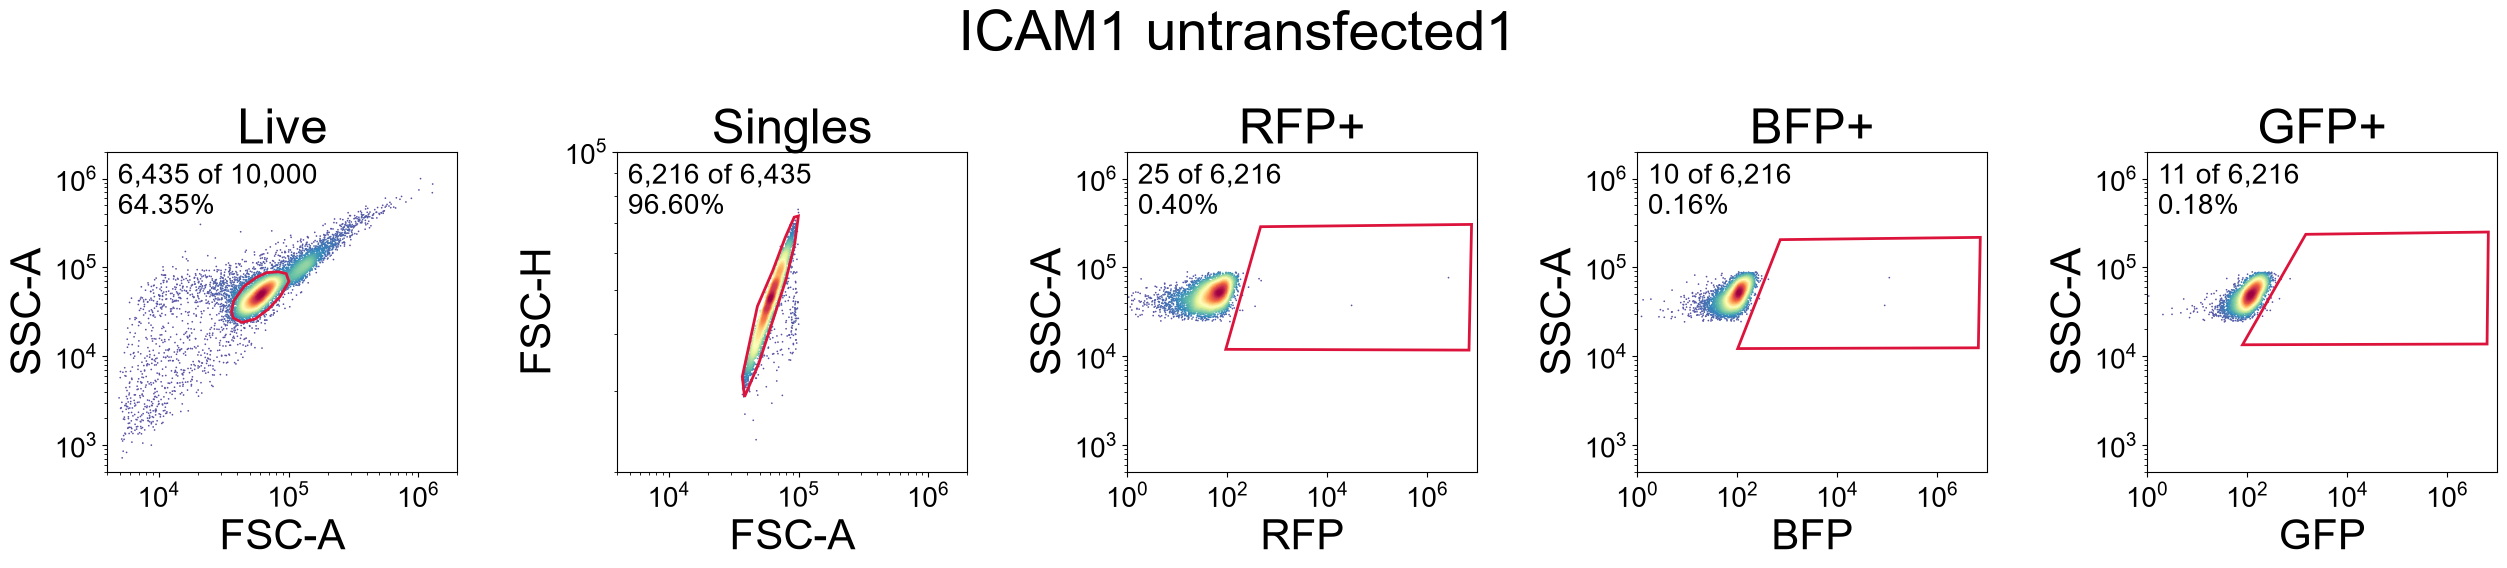

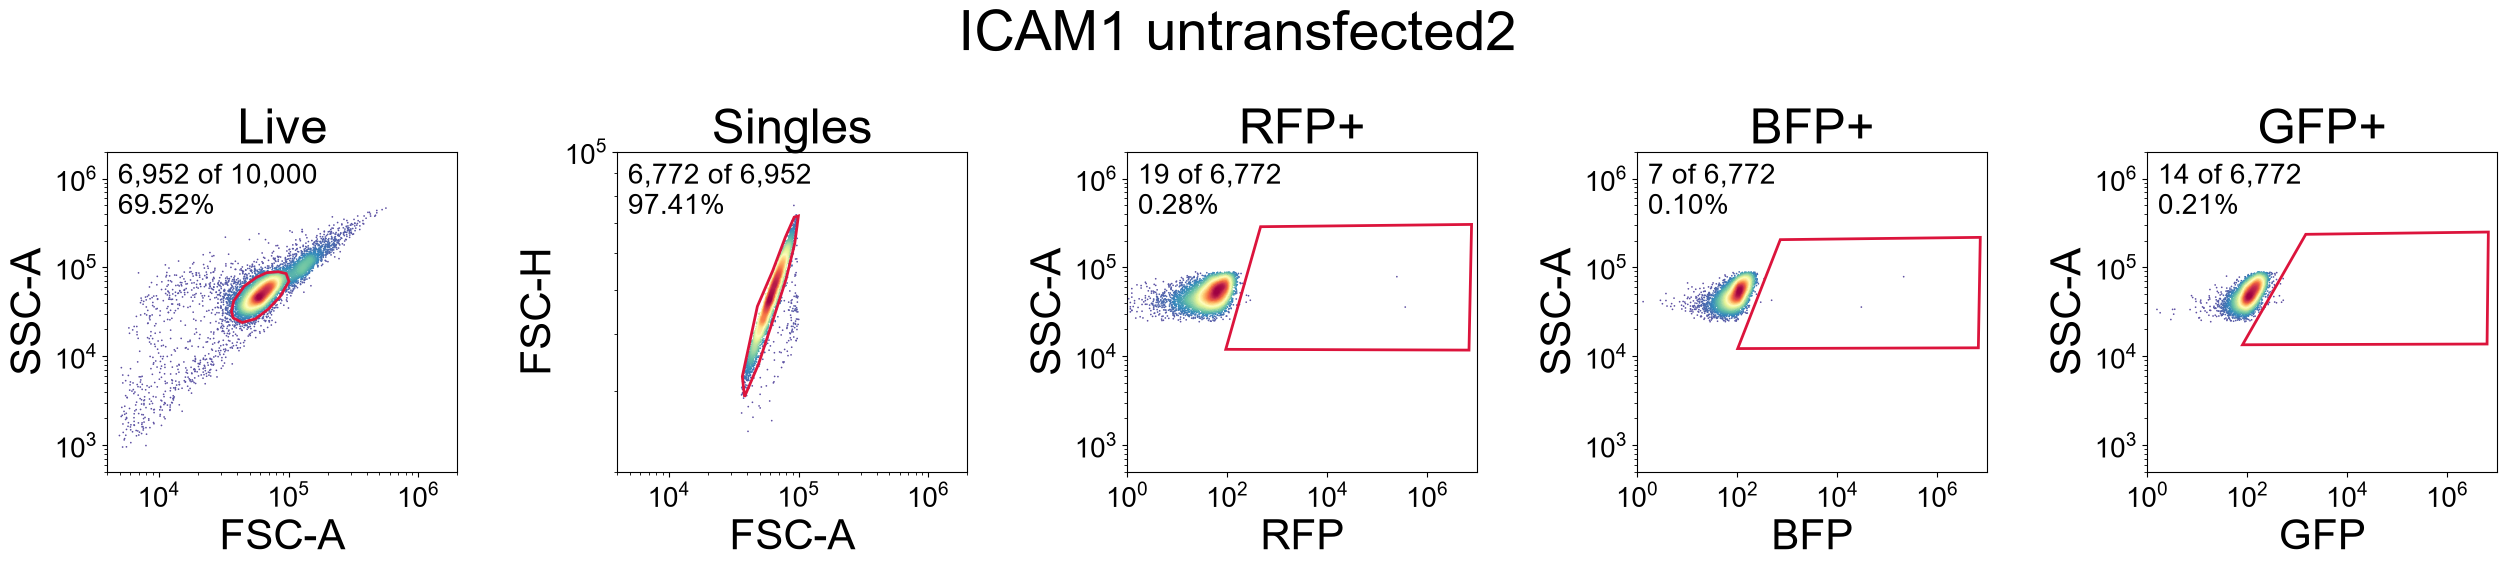

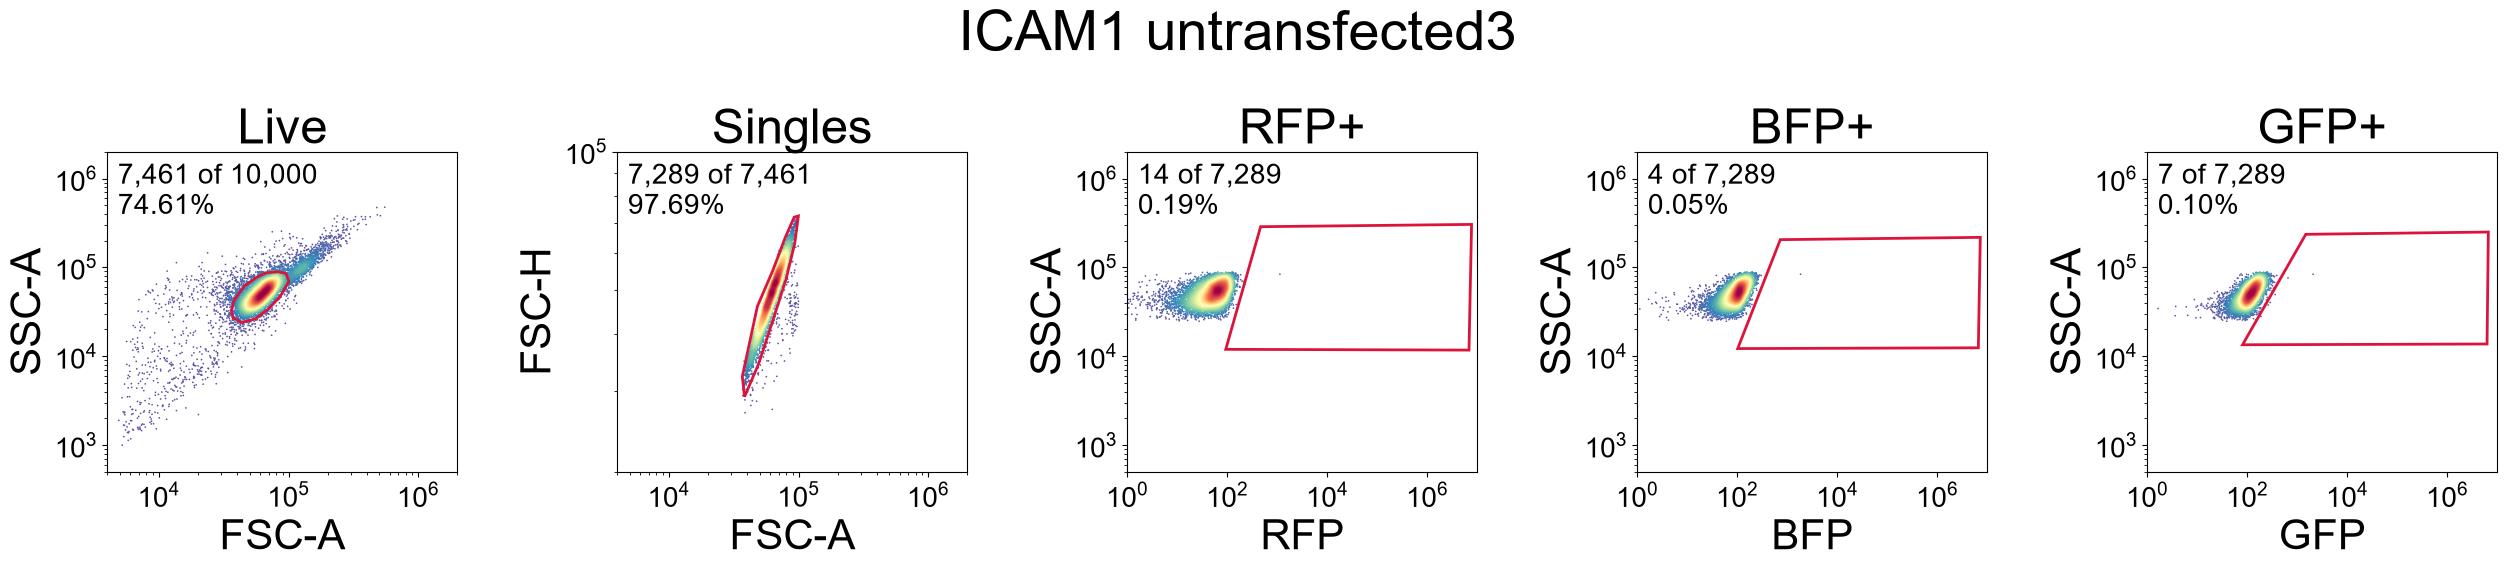

,Sample,n_singles,pct_rfp_of_singles,pct_bfp_of_singles,pct_gfp_of_singles
0,untransfected_1,6216,0.402188,0.160875,0.176963
1,untransfected_2,6772,0.280567,0.103367,0.206734
2,untransfected_3,7289,0.192070,0.054877,0.096035


In [7]:
un_names = [name for name in sorted(cells) if name.rsplit('_', 1)[0] == 'untransfected']
print("untransfected wells:", un_names)

# (title, x channel, y channel, gate, column of cells entering, x limits, y limits)
# RFP, BFP and GFP all start from 'in_singles' -- no cascade between the colors.
untransfected_STEPS = [
    ('Live',    'FSC-A', 'SSC-A', 'live',    None,         FSC_LIM, SSC_LIM),
    ('Singles', 'FSC-A', 'FSC-H', 'singles', 'in_live',    FSC_LIM, FSC_H_LIM),
    ('RFP+',    'RFP',   'SSC-A', 'rfp',     'in_singles', RFP_LIM, SSC_LIM),
    ('BFP+',    'BFP',   'SSC-A', 'bfp',     'in_singles', BFP_LIM, SSC_LIM),
    ('GFP+',    'GFP',   'SSC-A', 'gfp',     'in_singles', GFP_LIM, SSC_LIM),
]

# Text sizes (pt) -- the matplotlib default is 10
TICK_SIZE     = 20      # also used for the counts / percent inside each plot
LABEL_SIZE    = 30
TITLE_SIZE    = 35
SUPTITLE_SIZE = 40

# Layout (inches) -- every panel is AX_W x AX_H; the figure grows around them
AX_W, AX_H = 3.5, 3.2
GAP    = 1.6    # between panels: room for y tick labels + y label
LEFT   = 1.6
BOTTOM = 1.3
TOP    = 0.9    # room for the one-line panel titles


def plot_un_gating(name, save=False):
    df = cells[name]
    n = len(untransfected_STEPS)
    fig_w = LEFT + n * AX_W + (n - 1) * GAP + 0.3
    fig_h = BOTTOM + AX_H + TOP
    fig = plt.figure(figsize=(fig_w, fig_h))
    axes = [fig.add_axes([(LEFT + k * (AX_W + GAP)) / fig_w, BOTTOM / fig_h,
                          AX_W / fig_w, AX_H / fig_h]) for k in range(n)]
    pcts = {}

    for ax, step in zip(axes, untransfected_STEPS):
        title, xcol, ycol, gate_name, entering, xlim, ylim = step

        shown = df if entering is None else df[df[entering]]
        passed = inside(shown, xcol, ycol, gates[gate_name]['vertices'])
        density_scatter(ax, shown[xcol], shown[ycol], xlim, ylim)
        ax.add_patch(plt.Polygon(gates[gate_name]['vertices'], closed=True,
                                 fill=False, edgecolor='crimson', linewidth=2))

        n_in, n_entering = passed.sum(), len(shown)
        pct = 100 * n_in / n_entering if n_entering else np.nan
        pcts[gate_name] = pct
        ax.set_title(title, fontsize=TITLE_SIZE)
        ax.text(0.03, 0.97, f"{n_in:,} of {n_entering:,}\n{pct:.2f}%",
                transform=ax.transAxes, ha='left', va='top', fontsize=TICK_SIZE)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_xlabel(xcol, fontsize=LABEL_SIZE)
        ax.set_ylabel(ycol, fontsize=LABEL_SIZE)
        ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
        ax.tick_params(axis='both', which='minor', labelbottom=False, labelleft=False)

    fig.suptitle(f"{ASSAY} {name.replace('_', '')}", fontsize=SUPTITLE_SIZE,
                 y=1.0, va='bottom')
    if save:
        base = os.path.join(FIG_DIR, f"gating_untransfected_{ASSAY}_{name}")
        fig.savefig(base + '.pdf', bbox_inches='tight')   # for Illustrator
        fig.savefig(base + '.png', bbox_inches='tight')   # quick preview
    return fig, pcts


rows = []
for name in un_names:
    fig, pcts = plot_un_gating(name, save=SAVE_FIGS)
    plt.show()
    rows.append({
        'Sample': name,
        'n_singles': cells[name]['in_singles'].sum(),
        'pct_rfp_of_singles': pcts['rfp'],
        'pct_bfp_of_singles': pcts['bfp'],
        'pct_gfp_of_singles': pcts['gfp'],
    })

un_summary = pd.DataFrame(rows)
if SAVE_FIGS:
    un_summary.to_csv(os.path.join(FIG_DIR, f"gating_untransfected_summary_{ASSAY}.csv"), index=False)
    print(f"saved {len(un_names)} untransfected figures + summary to {FIG_DIR}")
un_summary


In [8]:
# Median GFP of live single cells (the same population shown in the GFP+ panel above)
mfi_rows = []
for name in un_names:
    df = cells[name]
    condition, replicate = name.rsplit('_', 1)
    mfi_rows.append({
        'Sample': name,
        'Condition': condition,
        'Replicate': int(replicate),
        'live_single_gfp': df.loc[df['in_singles'], 'GFP'].median(),
        'pct_gfp': 100 * inside(df[df['in_singles']], 'GFP', 'SSC-A', gates['gfp']['vertices']).mean(),

    })

un_gfp_mfi = pd.DataFrame(mfi_rows)
un_gfp_mfi

,Sample,Condition,Replicate,live_single_gfp,pct_gfp
0,untransfected_1,untransfected,1,115.313263,0.176963
1,untransfected_2,untransfected,2,113.702293,0.206734
2,untransfected_3,untransfected,3,115.554878,0.096035
